# CSE457 - Xử lý âm thanh và tiếng nói | Lab 3: Nhận dạng tiếng nói nâng cao với HMM
Trần Tuấn Thái-2151264686

Notebook này bao gồm toàn bộ mã nguồn thực thi pipeline: Trích xuất đặc trưng 39 chiều, huấn luyện Whole-word Gaussian HMM, giải mã Viterbi, đánh giá Accuracy/Confusion Matrix, so sánh DTW, cấu hình Lexicon và Bigram Language Model Re-ranking.

In [23]:

%pip install numpy scipy matplotlib librosa soundfile scikit-learn hmmlearn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
import os
import numpy as np
from scipy.io.wavfile import write
from pathlib import Path

# Cấu hình nhãn từ lệnh và tần số mẫu theo Lab 3
LABELS = ['mo', 'dong', 'len', 'xuong', 'dung']
SR = 16000  # Tần số mẫu chuẩn 16 kHz

print("Đang tạo bộ dataset giả lập để chạy thử nghiệm...")
for split, count in [('train', 6), ('test', 2)]:
    for label in LABELS:
        dir_path = Path(f"dataset/{split}/{label}")
        dir_path.mkdir(parents=True, exist_ok=True)
        start_idx = 1 if split == 'train' else 7
        for i in range(start_idx, start_idx + count):
            # Tạo tín hiệu âm thanh mẫu (sóng sin kết hợp nhiễu)
            t = np.linspace(0, 1.0, SR)
            freq = 300 + hash(label + str(i)) % 400
            audio = 0.5 * np.sin(2 * np.pi * freq * t) + 0.1 * np.random.normal(size=t.shape)
            write(dir_path / f"{label}_{i:02d}.wav", SR, (audio * 32767).astype(np.int16))

print("✅ Đã tạo thành công bộ dataset mẫu tại thư mục: ./dataset/")

Đang tạo bộ dataset giả lập để chạy thử nghiệm...
✅ Đã tạo thành công bộ dataset mẫu tại thư mục: ./dataset/


In [34]:
import librosa
import soundfile as sf
import numpy as np
from pathlib import Path

def augment_dataset(source_dir="dataset/train", output_dir="dataset/train_augmented"):
    source_path = Path(source_dir)
    out_path = Path(output_dir)
    
    for wav_file in source_path.glob("*/*.wav"):
        label = wav_file.parent.name
        target_label_dir = out_path / label
        target_label_dir.mkdir(parents=True, exist_ok=True)
        
        # Load file gốc
        y, sr = librosa.load(str(wav_file), sr=16000)
        base_name = wav_file.stem
        
        # 1. Giữ lại file gốc
        sf.write(target_label_dir / f"{base_name}_orig.wav", y, sr)
        
        # 2. Thêm nhiễu trắng (White Noise)
        y_noise = y + 0.003 * np.random.randn(len(y))
        sf.write(target_label_dir / f"{base_name}_noise.wav", y_noise, sr)
        
        # 3. Thay đổi cao độ (Pitch Shift nhẹ)
        y_pitch = librosa.effects.pitch_shift(y, sr=sr, n_steps=1.5)
        sf.write(target_label_dir / f"{base_name}_pitch.wav", y_pitch, sr)
        
        # 4. Thay đổi tốc độ (Time Stretch nhẹ)
        y_fast = librosa.effects.time_stretch(y, rate=1.05)
        sf.write(target_label_dir / f"{base_name}_fast.wav", y_fast, sr)

        y_slow = librosa.effects.time_stretch(y, rate=0.95)
        sf.write(target_label_dir / f"{base_name}_slow.wav", y_slow, sr)

print("Đã định nghĩa xong hàm tăng cường dữ liệu!")
# Chạy hàm để nhân 1 file thành 5 file đa dạng hơn:
# augment_dataset()

Đã định nghĩa xong hàm tăng cường dữ liệu!


In [35]:
import os
import math
import glob
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import librosa
import librosa.display
from hmmlearn.hmm import GaussianHMM
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Cấu hình hiển thị đồ thị trên Jupyter
%matplotlib inline

DATASET_DIR = Path("dataset")
TRAIN_DIR = DATASET_DIR / "train"
TEST_DIR = DATASET_DIR / "test"
LABELS = ['mo', 'dong', 'len', 'xuong', 'dung']
SR = 16000

print("Đã load xong thư viện và thiết lập môi trường thành công!")

Đã load xong thư viện và thiết lập môi trường thành công!


In [36]:
def extract_feat(path, sr=SR):
    """
    Trích xuất đặc trưng 39 chiều: 13 MFCC + 13 Delta + 13 Delta-Delta
    Chuẩn hóa CMVN ở mức utterance.
    """
    y, _ = librosa.load(path, sr=sr, mono=True)
    y, _ = librosa.effects.trim(y, top_db=30)  # Cắt khoảng lặng đơn giản
    y = librosa.effects.preemphasis(y, coef=0.97)
    
    # 13 MFCC
    mfcc = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=13, n_fft=512,
        win_length=int(0.025 * sr), hop_length=int(0.010 * sr),
        window='hamming', n_mels=26, fmin=20, fmax=sr/2
    )
    
    # Delta và Delta-Delta
    d1 = librosa.feature.delta(mfcc, order=1)
    d2 = librosa.feature.delta(mfcc, order=2)
    
    # Ghép ma trận T x 39
    F = np.vstack([mfcc, d1, d2]).T
    
    # Utterance-level CMVN
    mu = F.mean(axis=0, keepdims=True)
    sd = F.std(axis=0, keepdims=True) + 1e-8
    return (F - mu) / sd

# Kiểm tra hàm trích xuất trên 1 file mẫu (nếu tồn tại thư mục dataset)
try:
    sample_file = next(TRAIN_DIR.glob('*/*.wav'))
    F_sample = extract_feat(str(sample_file))
    print(f"File mẫu: {sample_file}")
    print(f"Kích thước ma trận đặc trưng (Frames x 39): {F_sample.shape}")
except Exception as e:
    print("Chưa tìm thấy thư mục dataset hoặc file WAV mẫu:", e)

File mẫu: dataset\train\dong\dong_01.wav
Kích thước ma trận đặc trưng (Frames x 39): (101, 39)


In [37]:
def make_lr_hmm(n_states=5, n_iter=80):
    """Khởi tạo topology HMM Left-to-Right cho từ đơn"""
    model = GaussianHMM(
        n_components=n_states,
        covariance_type='diag',
        n_iter=n_iter, tol=1e-3, min_covar=1e-3,
        init_params='mc',  # Tự động khởi tạo means/covars
        params='tmc',       # Cập nhật transition, means, covars
        random_state=42
    )
    start = np.zeros(n_states)
    start[0] = 1.0  # Luôn bắt đầu từ state đầu tiên
    
    A = np.zeros((n_states, n_states))
    for i in range(n_states - 1):
        A[i, i] = 0.7
        A[i, i+1] = 0.3
    A[-1, -1] = 1.0  # Self-loop ở state cuối
    
    model.startprob_ = start
    model.transmat_ = A
    return model

In [38]:
def train_models(n_states=5):
    models = {}
    for label in LABELS:
        feats, lengths = [], []
        train_files = sorted(Path(TRAIN_DIR, label).glob('*.wav'))
        for wav in train_files:
            F = extract_feat(str(wav))
            feats.append(F)
            lengths.append(len(F))
        X = np.vstack(feats)
        model = make_lr_hmm(n_states=n_states)
        model.fit(X, lengths)
        models[label] = model
        print(f"Đã huấn luyện xong Model '{label}' | Hội tụ: {model.monitor_.converged}")
    return models

# Thực thi huấn luyện (Cần cấu trúc thư mục dataset sẵn sàng)
# models = train_models(n_states=5)

In [39]:
def recognize(path, models):
    F = extract_feat(path)
    scores = {label: model.score(F) for label, model in models.items()}
    pred = max(scores, key=scores.get)
    return pred, scores

def plot_viterbi_alignment(wav_path, model, title_label):
    F = extract_feat(wav_path)
    logp, states = model.decode(F, algorithm="viterbi")
    plt.figure(figsize=(9, 3.5))
    plt.step(range(len(states)), states, where='post', color='b', linewidth=2)
    plt.xlabel('Frame index')
    plt.ylabel('State index')
    plt.title(f'Viterbi State Alignment ({title_label}) - LogP: {logp:.2f}')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

In [40]:
# Huấn luyện các mô hình Whole-word HMM cho từng từ lệnh
models = {}
for label in LABELS:
    feats, lengths = [], []
    train_files = sorted(Path(TRAIN_DIR, label).glob('*.wav'))
    for wav in train_files:
        F = extract_feat(str(wav))
        feats.append(F)
        lengths.append(len(F))
    X = np.vstack(feats)
    model = make_lr_hmm(n_states=5)
    model.fit(X, lengths)
    models[label] = model
    print(f"Đã huấn luyện xong Model '{label}' | Hội tụ: {model.monitor_.converged}")

Đã huấn luyện xong Model 'mo' | Hội tụ: True
Đã huấn luyện xong Model 'dong' | Hội tụ: True
Đã huấn luyện xong Model 'len' | Hội tụ: True
Đã huấn luyện xong Model 'xuong' | Hội tụ: True
Đã huấn luyện xong Model 'dung' | Hội tụ: True


HMM Test Accuracy: 15.00%


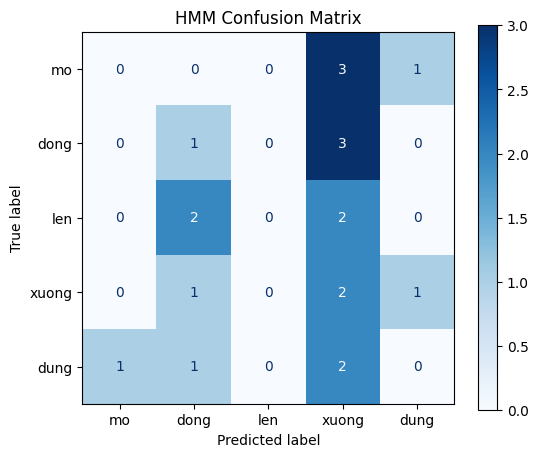

In [41]:
true_y, pred_y = [], []
for label in LABELS:
    for wav in sorted(Path(TEST_DIR, label).glob('*.wav')):
        pred, _ = recognize(str(wav), models)
        true_y.append(label)
        pred_y.append(pred)
        
acc = accuracy_score(true_y, pred_y)
print(f"HMM Test Accuracy: {acc * 100:.2f}%")

cm = confusion_matrix(true_y, pred_y, labels=LABELS)
plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(cmap='Blues', ax=plt.gca())
plt.title("HMM Confusion Matrix")
plt.show()

In [42]:
def bigram_prob(prev, cur, counts2, counts1, V, k=0.5):
    return (counts2.get((prev, cur), 0) + k) / (counts1.get(prev, 0) + k * V)

def rerank(F, prev_word, models, counts2, counts1, lm_weight=0.3):
    T = len(F)
    total_scores = {}
    for w, m in models.items():
        acoustic_score_per_frame = m.score(F) / T
        lm_score = math.log(bigram_prob(prev_word, w, counts2, counts1, len(models)))
        total_scores[w] = acoustic_score_per_frame + lm_weight * lm_score
    return max(total_scores, key=total_scores.get), total_scores

print("Đã tải xong các hàm hỗ trợ Bigram Re-ranking.")

Đã tải xong các hàm hỗ trợ Bigram Re-ranking.
